 Enquanto o notebook 03 explorou os metadados (idade, sexo, site, diagnóstico), este notebook explora os dados de conectividade já calculados buscando padrões que orientem decisões de modelagem. A pergunta central aqui é: existe algum sinal visível de que TEA e controle têm padrões de conectividade diferentes, e esse sinal não está sendo dominado pelo efeito de site?

**Objetivo:** Análise exploratória da conectividade: PCA, médias por grupo e diferença TEA − Controle.

**Entradas:** `Data/conectivity/connectivity_matrices_abide_validado.pkl` (notebook 05), `Data/raw/phenotypic_abide.csv`.

**Processamento:** PCA (2 componentes), matriz média TEA, matriz média Controle e diferença.

**Saídas:** `Figures/06_*.png`, `Results/06_analise_exploratoria_conectividade.pkl`.

In [ ]:
# ------------------------------------------------------------
# Configuração do projeto (execução local — VS Code)
# Garante que a raiz do projeto esteja no sys.path, funcionando tanto se o
# diretório de trabalho do kernel for notebooks/ quanto a raiz do projeto.
# ------------------------------------------------------------
import sys
from pathlib import Path

_raiz = Path.cwd().resolve()
for _cand in (_raiz, *_raiz.parents):
    if (_cand / 'src' / 'config.py').exists():
        _raiz = _cand
        break
else:
    raise RuntimeError(
        'Não foi possível localizar a pasta src/config.py a partir de '
        f'{Path.cwd()}. Abra a pasta TCC_TEA_TDAH/ no VS Code.'
    )
if str(_raiz) not in sys.path:
    sys.path.insert(0, str(_raiz))

import os
import random
import numpy as np

from src.config import BASE_DIR, PATHS, SEED, criar_pastas
from src.utils import exigir_arquivo

criar_pastas()

random.seed(SEED)
np.random.seed(SEED)

print('Projeto (BASE_DIR) =', BASE_DIR)

In [3]:
exigir_arquivo(PATHS['conectivity'] / 'connectivity_matrices_abide_validado.pkl', '05_Validacao_ABIDE.ipynb')
exigir_arquivo(PATHS['raw'] / 'phenotypic_abide.csv', '02_Download_ABIDE.ipynb')

import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from nilearn.connectome import sym_matrix_to_vec

with open(os.path.join(PATHS['conectivity'], 'connectivity_matrices_abide_validado.pkl'), 'rb') as f:
    conn_dict = pickle.load(f)

phenotypic = pd.read_csv(os.path.join(PATHS['raw'], 'phenotypic_abide.csv')).set_index('SUB_ID')

sub_ids = list(conn_dict.keys())
matrices = np.array([conn_dict[s] for s in sub_ids])
vetores = sym_matrix_to_vec(matrices, discard_diagonal=True)

labels = phenotypic.loc[sub_ids, 'DX_GROUP'].values     # 1=TEA, 2=Controle
sites = phenotypic.loc[sub_ids, 'SITE_ID'].values

print('Vetores de conectividade:', vetores.shape)

Vetores de conectividade: (871, 19900)


## PCA para visualização — reduz 19.900 features para 2 componentes

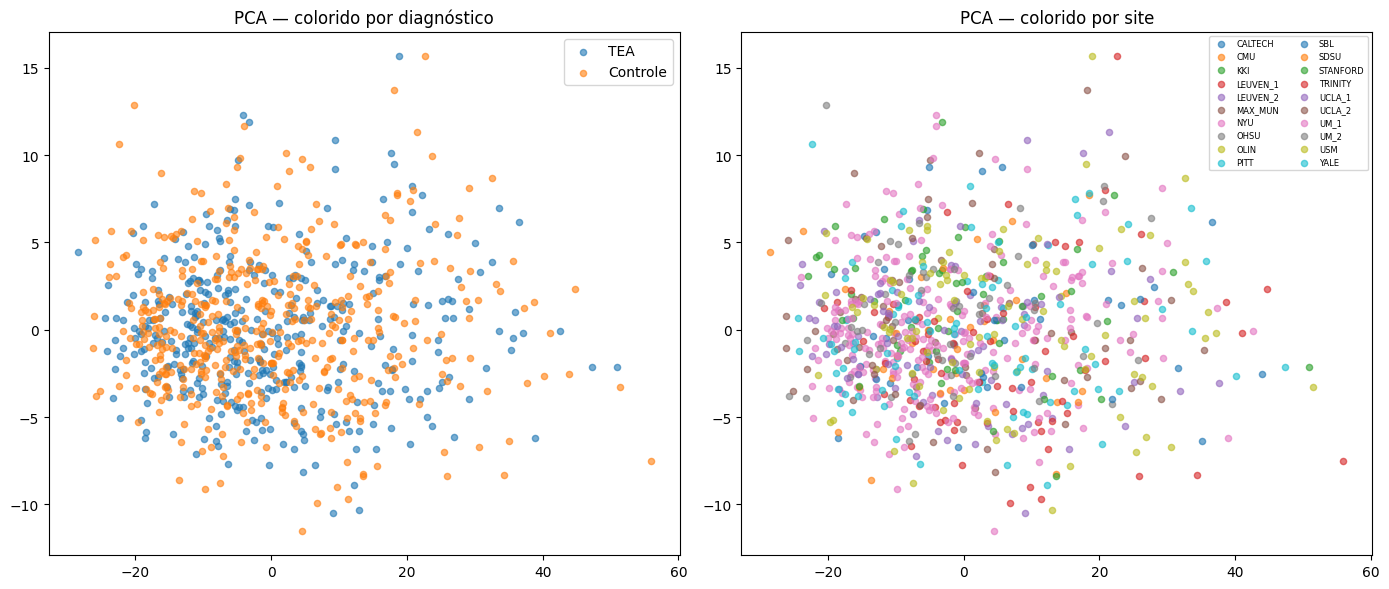

Variância explicada pelos 2 componentes: 31.38%


In [4]:
pca = PCA(n_components=2, random_state=SEED)
proj = pca.fit_transform(vetores)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for label, nome in zip([1, 2], ['TEA', 'Controle']):
    mask = labels == label
    axes[0].scatter(proj[mask, 0], proj[mask, 1], label=nome, alpha=0.6, s=20)
axes[0].set_title('PCA — colorido por diagnóstico')
axes[0].legend()

sites_unicos = np.unique(sites)
for s in sites_unicos:
    mask = sites == s
    axes[1].scatter(proj[mask, 0], proj[mask, 1], label=s, alpha=0.6, s=20)
axes[1].set_title('PCA — colorido por site')
axes[1].legend(fontsize=6, ncol=2)

plt.tight_layout()
plt.savefig(os.path.join(PATHS['figures'], '06_pca_diagnostico_vs_site.png'), dpi=150)
plt.show()

print(f'Variância explicada pelos 2 componentes: {pca.explained_variance_ratio_.sum():.2%}')

## Matriz de conectividade média por grupo, e diferença entre grupos

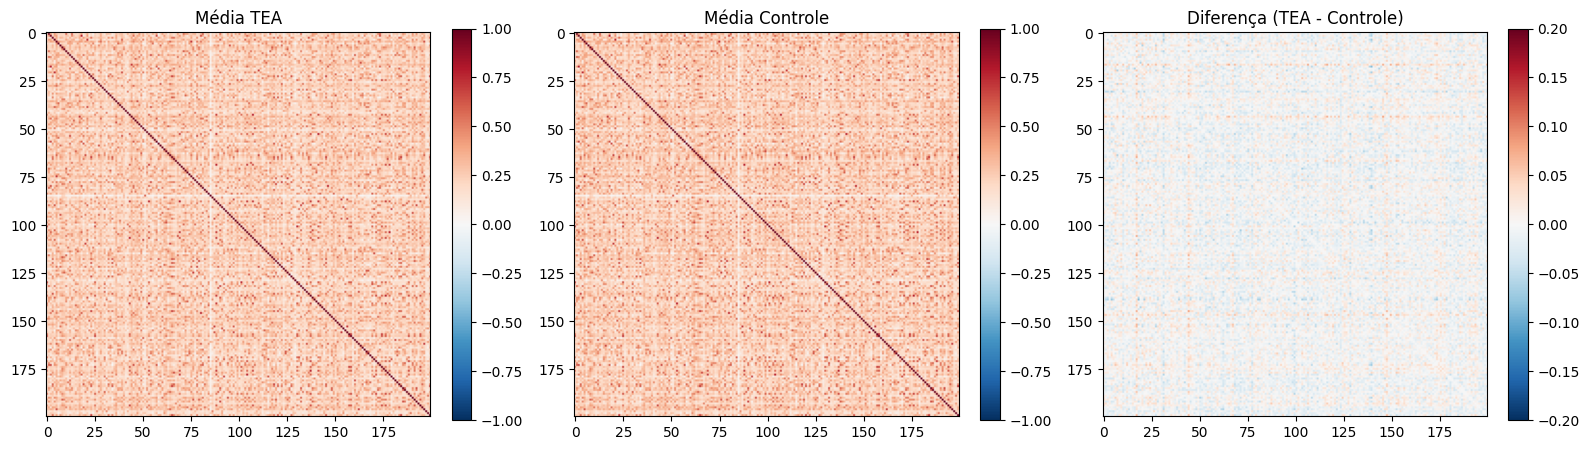

In [5]:
media_tea = matrices[labels == 1].mean(axis=0)
media_controle = matrices[labels == 2].mean(axis=0)
diferenca = media_tea - media_controle

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, mat, titulo in zip(axes, [media_tea, media_controle, diferenca],
                             ['Média TEA', 'Média Controle', 'Diferença (TEA - Controle)']):
    im = ax.imshow(mat, cmap='RdBu_r', vmin=-1 if titulo != 'Diferença (TEA - Controle)' else -0.2,
                   vmax=1 if titulo != 'Diferença (TEA - Controle)' else 0.2)
    ax.set_title(titulo)
    plt.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.savefig(os.path.join(PATHS['figures'], '06_conectividade_media_por_grupo.png'), dpi=150)
plt.show()

In [7]:
resultado_06 = {
    'media_tea': media_tea,
    'media_controle': media_controle,
    'diferenca': diferenca,
    'pca_variancia_explicada': pca.explained_variance_ratio_,
}
with open(os.path.join(PATHS['results'], '06_analise_exploratoria_conectividade.pkl'), 'wb') as f:
    pickle.dump(resultado_06, f)

print('Resultados da análise exploratória salvos em Results.')

Resultados da análise exploratória salvos em Results.
